In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model, plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

from numpy.lib.stride_tricks import sliding_window_view

I0000 00:00:1794823335.306211 2723226 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794823335.339932 2723226 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794823336.057831 2723226 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h1> Import Data

Text(0.5, 0.98, 'All Data')

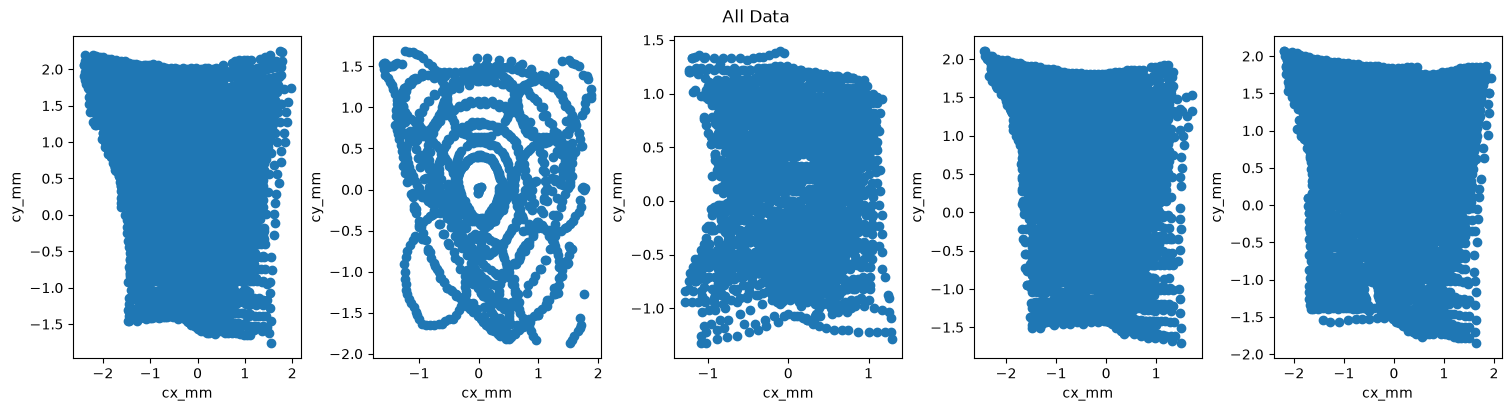

In [15]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_4 = pd.read_csv("processed_data/pred_data.csv", dtype="float32")

#remove nans
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_3 = data_3.dropna()

data_list = [ data_1, data_2, data_4, data_3, data_0]

fig, axs = plt.subplots(1, 5, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2>Concatenate

In [16]:
all_data = pd.concat(data_list, ignore_index=True)

In [17]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3, constrained_layout=True)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

<h3>Windows

This is a normal MLP but the input is a window

In [18]:
#function from https://machinelearningmastery.com/convert-time-series-supervised-learning-problem-python/
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	"""
	Frame a time series as a supervised learning dataset.
	Arguments:
		data: Sequence of observations as a list or NumPy array.
		n_in: Number of lag observations as input (X).
		n_out: Number of observations as output (y).
		dropnan: Boolean whether or not to drop rows with NaN values.
	Returns:
		Pandas DataFrame of series framed for supervised learning.
	"""
	n_vars = 1 if type(data) is list else data.shape[1]
	df = pd.DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(df.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(df.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = pd.concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg

In [22]:
dataset = all_data[["cx_mm", "cy_mm", "s0", "s1", "s2"]].reset_index(drop=True) #reset indexes as multiple datapoints combined

# values = dataset.values

window_size = 10

cxcy_window = series_to_supervised(dataset,window_size,1)

# cols_to_drop = cxcy_window.filter(regex="var3|var4|var5.*")
# inputs = cxcy_window.drop(list(cols_to_drop), axis=1)
 #change input window to include all motor values
# cxcy_window = cxcy_window.rename(columns={"var3(t)": "s0(t)", "var4(t)": "s1(t)", "var5(t)": "s2(t)"})
# outputs = cxcy_window[["s0(t)","s1(t)"]] #calculate s2(t) from s2 = -(s0 + s1)

# print(all_data["s2"][10:] == -(outputs["s0(t)"] + outputs["s1(t)"]))
outputs = cxcy_window[["var3(t)","var4(t)"]] #, "var5(t)" #don't predict s2 but keep it in training data
inputs = cxcy_window.drop(["var3(t)","var4(t)", "var5(t)"], axis=1)

inputs["cx_diff"] = inputs["var1(t)"].diff()
inputs["cy_diff"] = inputs["var2(t)"].diff()

inputs = inputs[1:]

display(cxcy_window.head(1))
display(inputs.head(2))
display(outputs.head(1))


,var1(t-10),var2(t-10),var3(t-10),var4(t-10),var5(t-10),var1(t-9),var2(t-9),var3(t-9),var4(t-9),var5(t-9),...,var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var1(t),var2(t),var3(t),var4(t),var5(t)
10,0.009091,0.0,0.0,0.0,0.0,-0.009091,0.0,0.0,0.0,0.0,...,0.863636,1.6,6144.0,-5289.0,-855.0,0.736364,1.6,6144.0,-4846.0,-1298.0


,var1(t-10),var2(t-10),var3(t-10),var4(t-10),var5(t-10),var1(t-9),var2(t-9),var3(t-9),var4(t-9),var5(t-9),...,var5(t-2),var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var1(t),var2(t),cx_diff,cy_diff
11,-0.009091,0.000000,0.0,0.0,0.0,1.972727,1.745455,6144.0,-8393.0,2249.0,...,-855.0,0.736364,1.6,6144.0,-4846.0,-1298.0,0.572727,1.600000,-0.163636,0.000000
12,1.972727,1.745455,6144.0,-8393.0,2249.0,1.827273,1.727273,6144.0,-7949.0,1805.0,...,-1298.0,0.572727,1.6,6144.0,-4402.0,-1742.0,0.390909,1.581818,-0.181818,-0.018182


,var3(t),var4(t)
10,6144.0,-4846.0


<h2>TimeSeriesSplit

In [23]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

def train_model(model, X_train, y_train, epochs=500, patience=30, verbose=0):
    """Train a model with early stopping and learning rate scheduling"""
    callbacks = [
        # tf.keras.callbacks.EarlyStopping(
        #     monitor='val_loss',
        #     patience=patience,
        #     restore_best_weights=True
        # ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=30,
            min_lr=1e-7
        )
    ]
    
    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=128,
        verbose=verbose,
        callbacks=callbacks,
        shuffle=False
    )
    
    return history

Fold 0:
  Train: index=0 to 2783 
  Test:  index=2784 to 5563
Fold 1:
  Train: index=0 to 5563 
  Test:  index=5564 to 8343
Fold 2:
  Train: index=0 to 8343 
  Test:  index=8344 to 11123
Fold 3:
  Train: index=0 to 11123 
  Test:  index=11124 to 13903
(11124, 54)
(11124, 54)
Epoch 1/500
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4777 - mae: 0.4559 - val_loss: 0.0893 - val_mae: 0.2185 - learning_rate: 0.0010
Epoch 2/500
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0916 - mae: 0.2191 - val_loss: 0.0594 - val_mae: 0.1779 - learning_rate: 0.0010
Epoch 3/500
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0559 - mae: 0.1656 - val_loss: 0.0440 - val_mae: 0.1521 - learning_rate: 0.0010
Epoch 4/500
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0410 - mae: 0.1406 - val_loss: 0.0344 - val_mae: 0.1312 - learning_rate: 0.0010
Epoch 5/500
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0341 - mae: 0.1277 - val_loss: 0.0298 - val_mae: 0.1229 - learning_rate: 0.0010
Epoch 6/500
70/70 ━

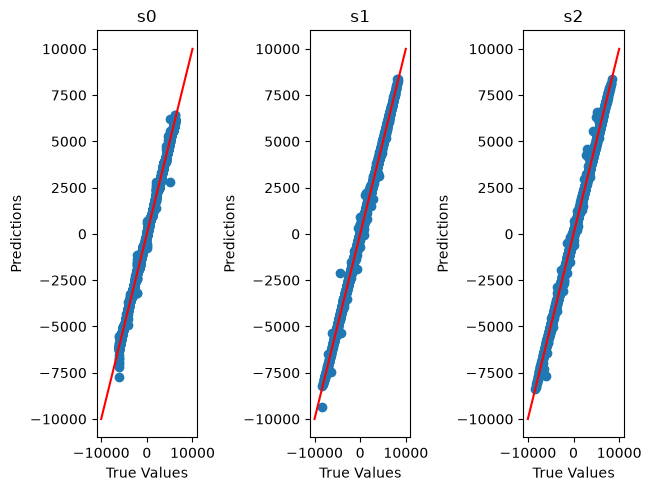

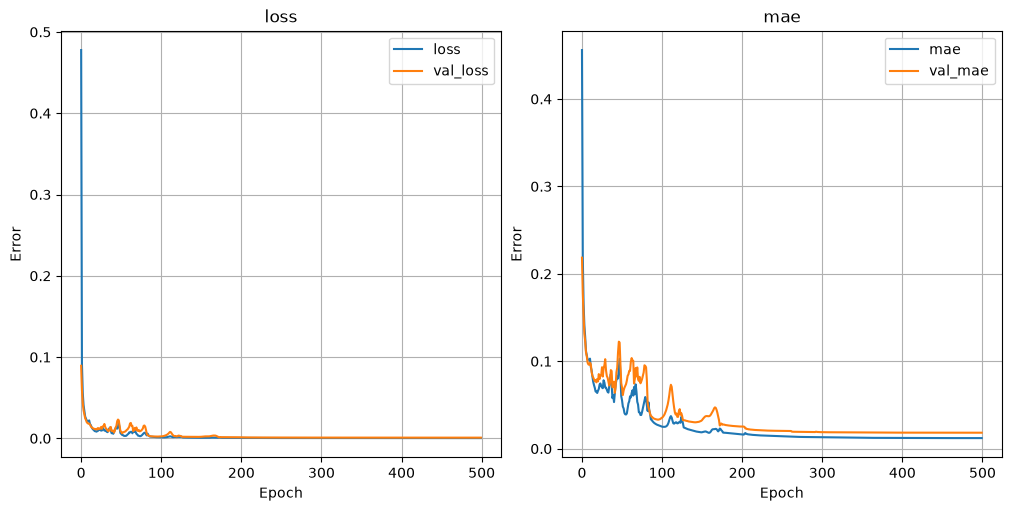

In [24]:

scores = []
train_indices = []
test_indices = []

tscv = TimeSeriesSplit(n_splits=4)
for i, (train_index, test_index) in enumerate(tscv.split(inputs)):

    print(f"Fold {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")

    train_indices = train_index
    test_indices = test_index
    #just want indices of final fold - 80:20 train:test


X_train, X_test = inputs.to_numpy()[train_index], inputs.to_numpy()[test_index]
y_train, y_test = outputs.to_numpy()[train_index], outputs.to_numpy()[test_index]

print(X_train.shape)
print(X_train.shape)
# model.summary() #investigate

scalerX = StandardScaler().fit(X_train)
scalerY = StandardScaler().fit(y_train)

X_train_scaled = scalerX.transform(X_train)
y_train_scaled = scalerY.transform(y_train)

X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

model = build_nn_model(X_train_scaled.shape[1], y_train_scaled.shape[1])

history = train_model(model, X_train_scaled, y_train_scaled, verbose=1, epochs=500)
y_pred = model.predict(X_test_scaled, verbose=0)

evaluate_model(f"Fold: {i}", y_test_scaled, y_pred, is_scaled=True)

# y_test_inverse = scalerY.inverse_transform(y_test)
y_pred_inverse = scalerY.inverse_transform(y_pred)

y_pred_df = pd.DataFrame(y_pred_inverse)
y_pred_df[2] = -(y_pred_df[0] + y_pred_df[1])

y_test_df = pd.DataFrame(y_test)
y_test_df[2] = -(y_test_df[0] + y_test_df[1])

for i in range(3): 
    evaluate_model(f"s{i}", y_test_df[i], y_pred_df[i], is_scaled=False)

plot_motors(y_test_df.to_numpy(), y_pred_df.to_numpy(), [-10000,10000])

error = mean_squared_error(y_test, y_pred)
scores.append(error)
plot_loss_and_mae(history)

# print("MSE scores for each fold:", scores)

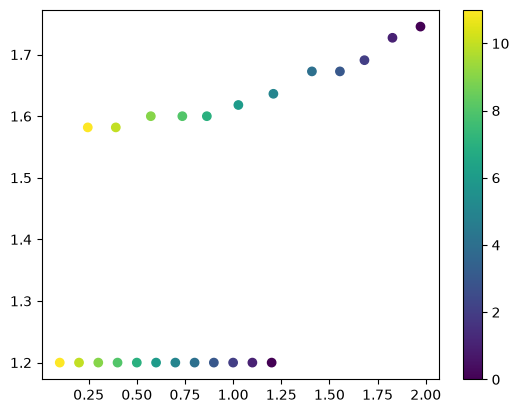

In [70]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv").head(window_size+2) #get basic snake scan x and y values
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.scatter(mesh0045_27Oct["cx_mm"], mesh0045_27Oct["cy_mm"], c=mesh0045_27Oct["point"])
plt.colorbar()


In [71]:
mesh0045_27Oct

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0,0.0,23.0545,1.2,1.2,1.200031,1.2,6144.0,-8393.0,2249.0,...,62.0,6.0,-64.0,-78.0,216.0,202.0,-217.0,-192.0,1.972727,1.745454
1,1,1.0,25.1289,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,64.0,6.0,-48.0,-76.0,232.0,204.0,-201.0,-190.0,1.827273,1.727273
2,2,2.0,27.2035,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,68.0,6.0,-32.0,-72.0,248.0,208.0,-185.0,-186.0,1.681818,1.690909
3,3,3.0,29.2619,0.9,1.2,0.900080,1.2,6144.0,-7063.0,919.0,...,70.0,6.0,-18.0,-70.0,262.0,210.0,-171.0,-184.0,1.554545,1.672727
4,4,4.0,31.3362,0.8,1.2,0.799946,1.2,6144.0,-6619.0,475.0,...,70.0,6.0,-2.0,-70.0,278.0,210.0,-155.0,-184.0,1.409091,1.672727
5,5,5.0,33.4113,0.7,1.2,0.700037,1.2,6144.0,-6176.0,32.0,...,74.0,6.0,20.0,-66.0,300.0,214.0,-133.0,-180.0,1.209091,1.636364
6,6,6.0,35.4868,0.6,1.2,0.599903,1.2,6144.0,-5732.0,-412.0,...,76.0,6.0,40.0,-64.0,320.0,216.0,-113.0,-178.0,1.027273,1.618182
7,7,7.0,37.5449,0.5,1.2,0.499994,1.2,6144.0,-5289.0,-855.0,...,78.0,6.0,58.0,-62.0,338.0,218.0,-95.0,-176.0,0.863636,1.600000
8,8,8.0,39.6205,0.4,1.2,0.400086,1.2,6144.0,-4846.0,-1298.0,...,78.0,6.0,72.0,-62.0,352.0,218.0,-81.0,-176.0,0.736364,1.600000
9,9,9.0,41.6958,0.3,1.2,0.299951,1.2,6144.0,-4402.0,-1742.0,...,78.0,6.0,90.0,-62.0,370.0,218.0,-63.0,-176.0,0.572727,1.600000


In [86]:
mesh0045_27Oct = mesh0045_27Oct[["cx_mm", "cy_mm", "s0", "s1", "s2"]]

# mesh0045_27Oct_dropped = mesh0045_27Oct[1:]


series_45 = series_to_supervised(mesh0045_27Oct, window_size, 1)

outputs_45 = series_45[["var3(t)","var4(t)", "var5(t)"]]

inputs_45 = series_45.drop(["var3(t)","var4(t)", "var5(t)"], axis=1)

inputs_45["cx_diff"] = inputs_45["var1(t)"].diff()
inputs_45["cy_diff"] = inputs_45["var2(t)"].diff()

inputs_45 = inputs_45[1:]

inputs_45

,var1(t-10),var2(t-10),var3(t-10),var4(t-10),var5(t-10),var1(t-9),var2(t-9),var3(t-9),var4(t-9),var5(t-9),...,var5(t-2),var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var1(t),var2(t),cx_diff,cy_diff
11,1.827273,1.727273,6144.0,-7949.0,1805.0,1.681818,1.690909,6144.0,-7506.0,1362.0,...,-1742.0,0.390909,1.581818,6144.0,-3959.0,-2185.0,0.245455,1.581818,-0.145455,0.0


In [93]:
inputs_45_scaled = scalerX.transform(inputs_45)

snake_predictions = model.predict(inputs_45_scaled)
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)
snake_pred_inverse = np.append(snake_pred_inverse, -(snake_pred_inverse[:,0] + snake_pred_inverse[:,1]))
print(snake_pred_inverse)
display(outputs_45[1:])
# np.savetxt("predictions/individual/window_10.csv", snake_pred_inverse, delimiter=',')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
[ 6121.485  -3872.8472 -2248.6377]


/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


,var3(t),var4(t),var5(t)
11,6144.0,-3515.0,-2629.0
